# **1. Bussines Understanding**

## **1.1 Latar Belakang**

Kesehatan mental mahasiswa dipengaruhi oleh berbagai aspek gaya hidup dan aktivitas akademik. Data ini menggambarkan hasil survei terhadap 10.000 mahasiswa yang mencakup kebiasaan sehari-hari, prestasi belajar, dan kesejahteraan mental sebagai bahan analisis berbasis data.

## **1.2 Tujuan**

Memabangun Machine Learning untuk memprediksi kesehatan mental mahasiswa

## **1.3 Masalah**

Dalam mendeteksi kesehatan mental masih menggunakan metode manual

## **1.4 Solusi**

Memabangun Machine Learning untuk memprediksi kesehatan mental mahasiswa secara otomatis menggunakan machine learning

## **1.5 Deskripsi Kolom**

* Age : Usia Mahasiswa(18 - 24 tahun)
* Gender : Jenis Kelamin
* Department : Bidang studi mahasiswa
* CGPA : Nilai IPK mahasiswa
* Sleep_Duration : Rata - rata jam tidur

## 2.0 Data Preparation

In [12]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
df = pd.read_csv('student_lifestyle_100k.csv')

In [14]:
print('Jumlah Baris :', df.shape[0])
print('================================')
print('Jumlah Kolom :', df.shape[1])
print('================================')
print('5 Data Pertama : ', df.head())

Jumlah Baris : 100000
Jumlah Kolom : 11
5 Data Pertama :     Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  Study_Hours  \
0        1001   22  Female      Science  3.50             7.3          3.3   
1        1002   20    Male  Engineering  2.72             5.5          7.2   
2        1003   20    Male      Medical  3.01             5.4          2.3   
3        1004   21    Male  Engineering  3.63             8.1          2.0   
4        1005   19    Male         Arts  3.14             6.8          2.6   

   Social_Media_Hours  Physical_Activity  Stress_Level  Depression  
0                 3.4                114             5       False  
1                 6.0                142             2       False  
2                 1.8                137             3       False  
3                 4.6                130             3       False  
4                 4.3                  4             6       False  


In [15]:
df.isnull().sum().sum()

np.int64(0)

In [16]:
df.duplicated().sum().sum()

np.int64(0)

In [17]:
print(df.info)
print(df.describe)

<bound method DataFrame.info of        Student_ID  Age  Gender   Department  CGPA  Sleep_Duration  \
0            1001   22  Female      Science  3.50             7.3   
1            1002   20    Male  Engineering  2.72             5.5   
2            1003   20    Male      Medical  3.01             5.4   
3            1004   21    Male  Engineering  3.63             8.1   
4            1005   19    Male         Arts  3.14             6.8   
...           ...  ...     ...          ...   ...             ...   
99995      100996   24  Female      Medical  2.02             7.0   
99996      100997   24    Male         Arts  2.33             5.0   
99997      100998   24  Female  Engineering  2.23             6.5   
99998      100999   19    Male  Engineering  3.61             6.1   
99999      101000   24  Female      Medical  2.10             7.9   

       Study_Hours  Social_Media_Hours  Physical_Activity  Stress_Level  \
0              3.3                 3.4                114       

## 3.0 Exploratoty Data Analyst

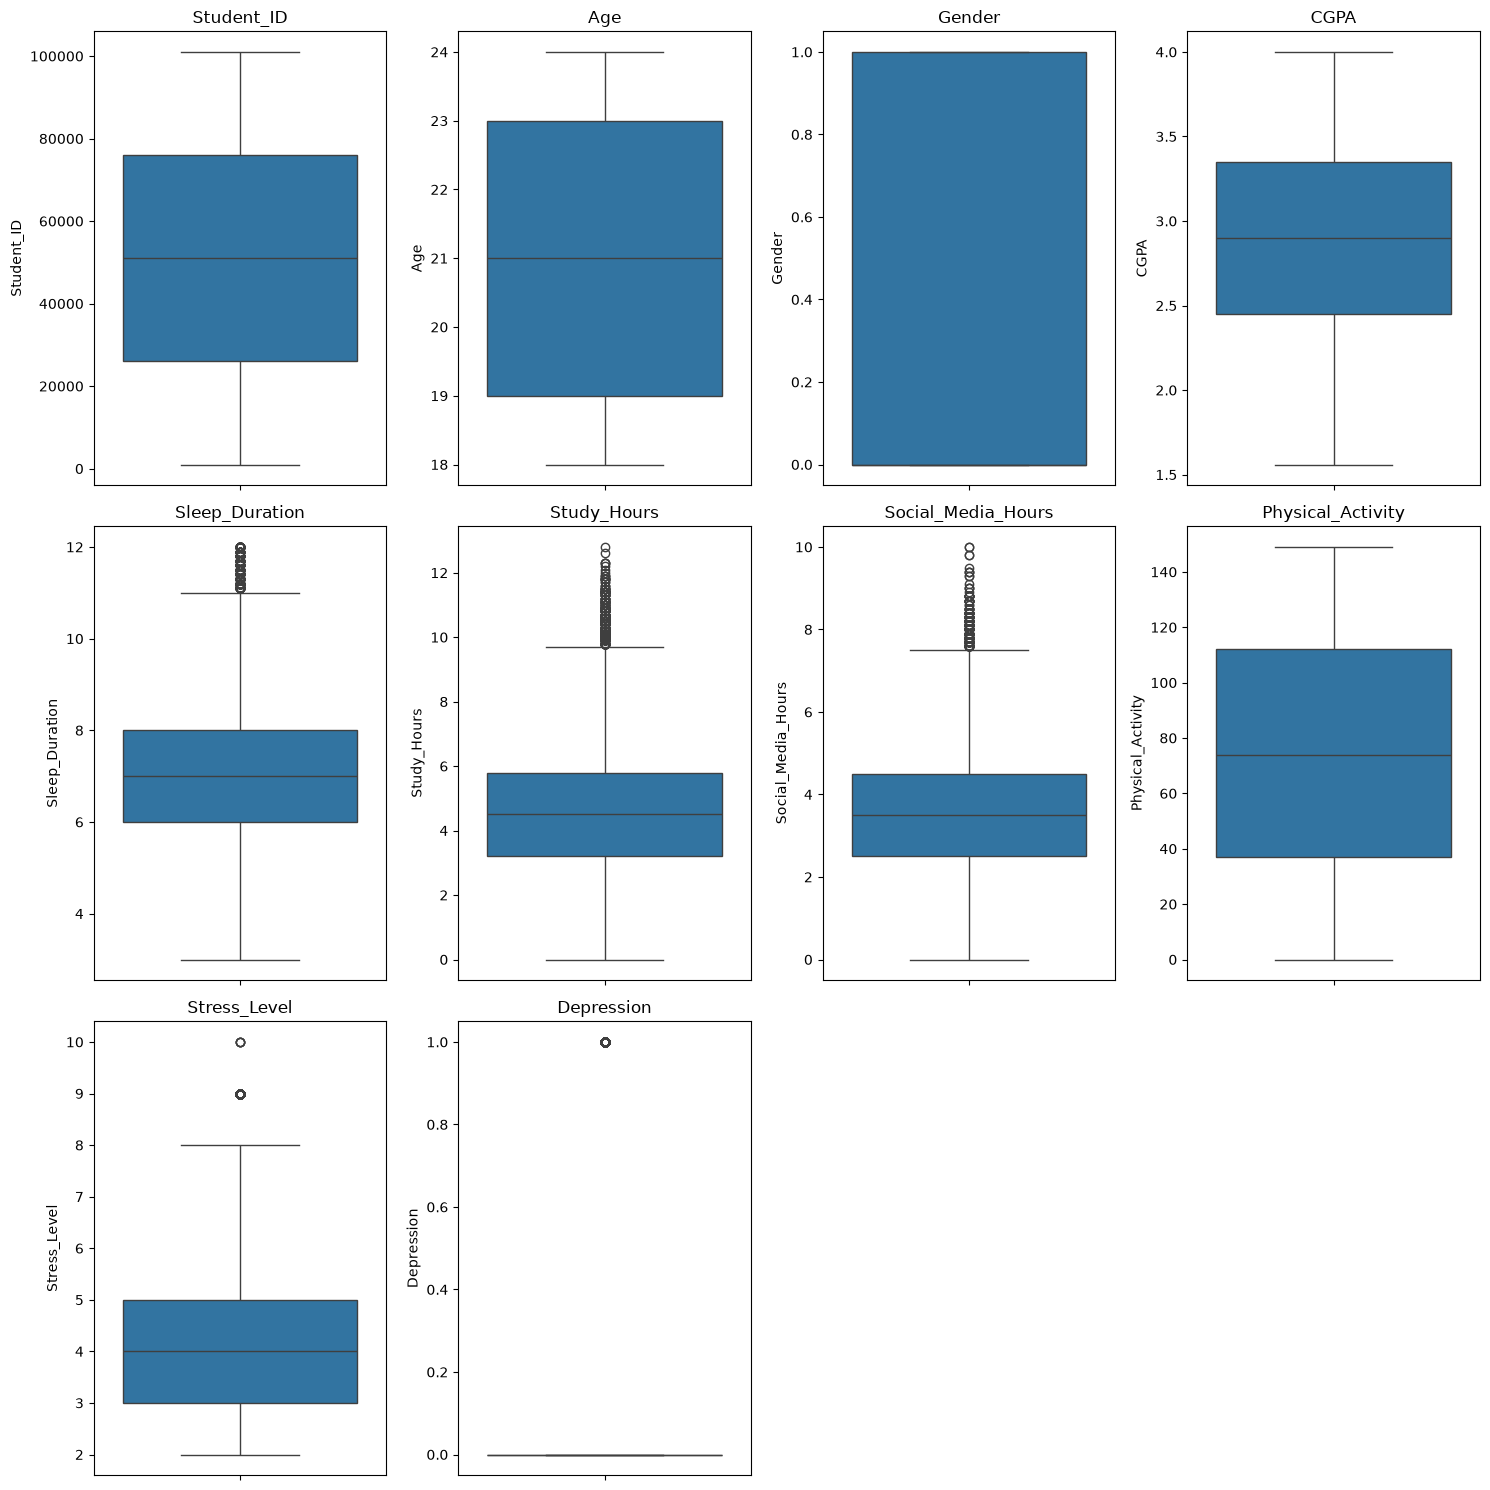

In [32]:
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15,15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 4, i)
    sns.boxplot(data=df[col])
    plt.title(col)
    
plt.tight_layout()
plt.show()

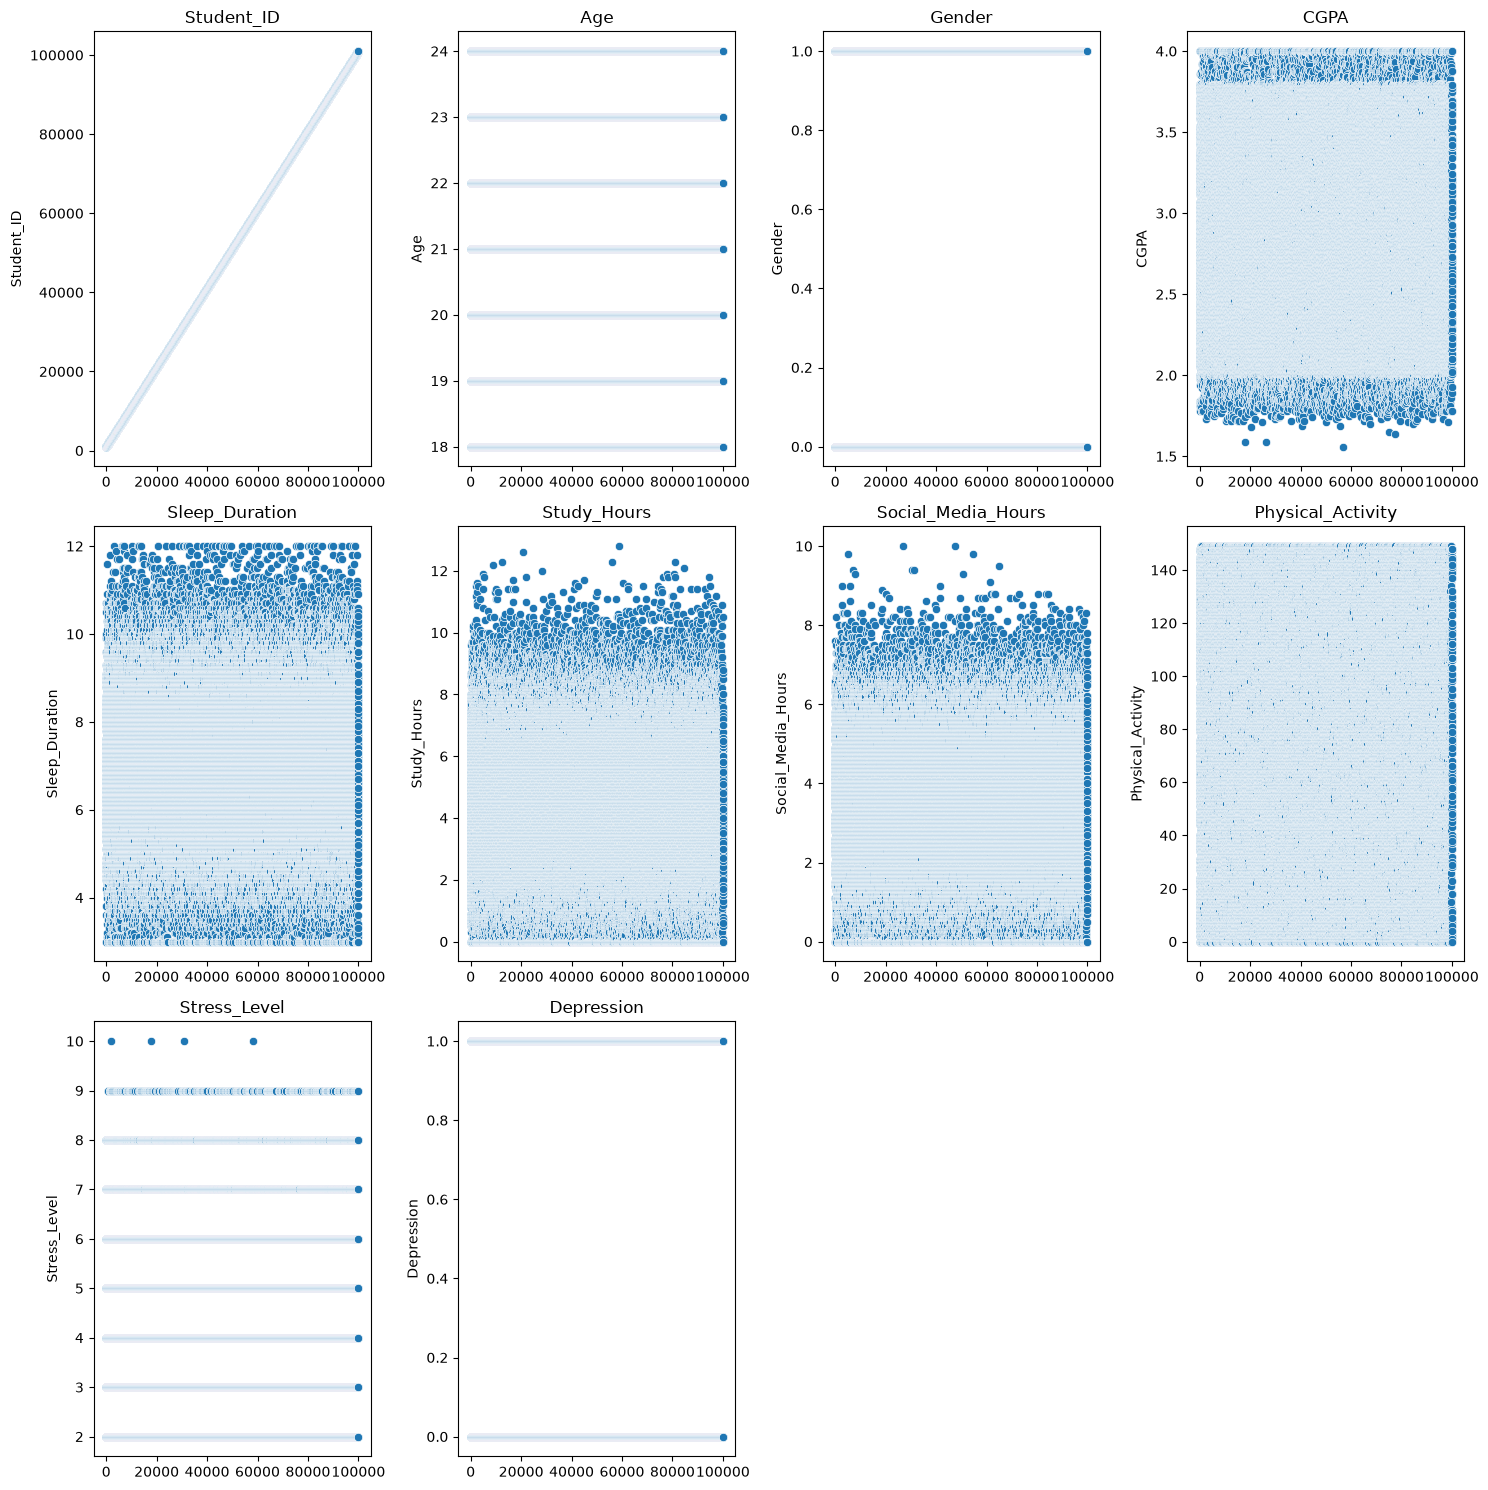

In [35]:
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15,15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 4, i)
    sns.scatterplot(data=df[col])
    plt.title(col)
    
plt.tight_layout()
plt.show()

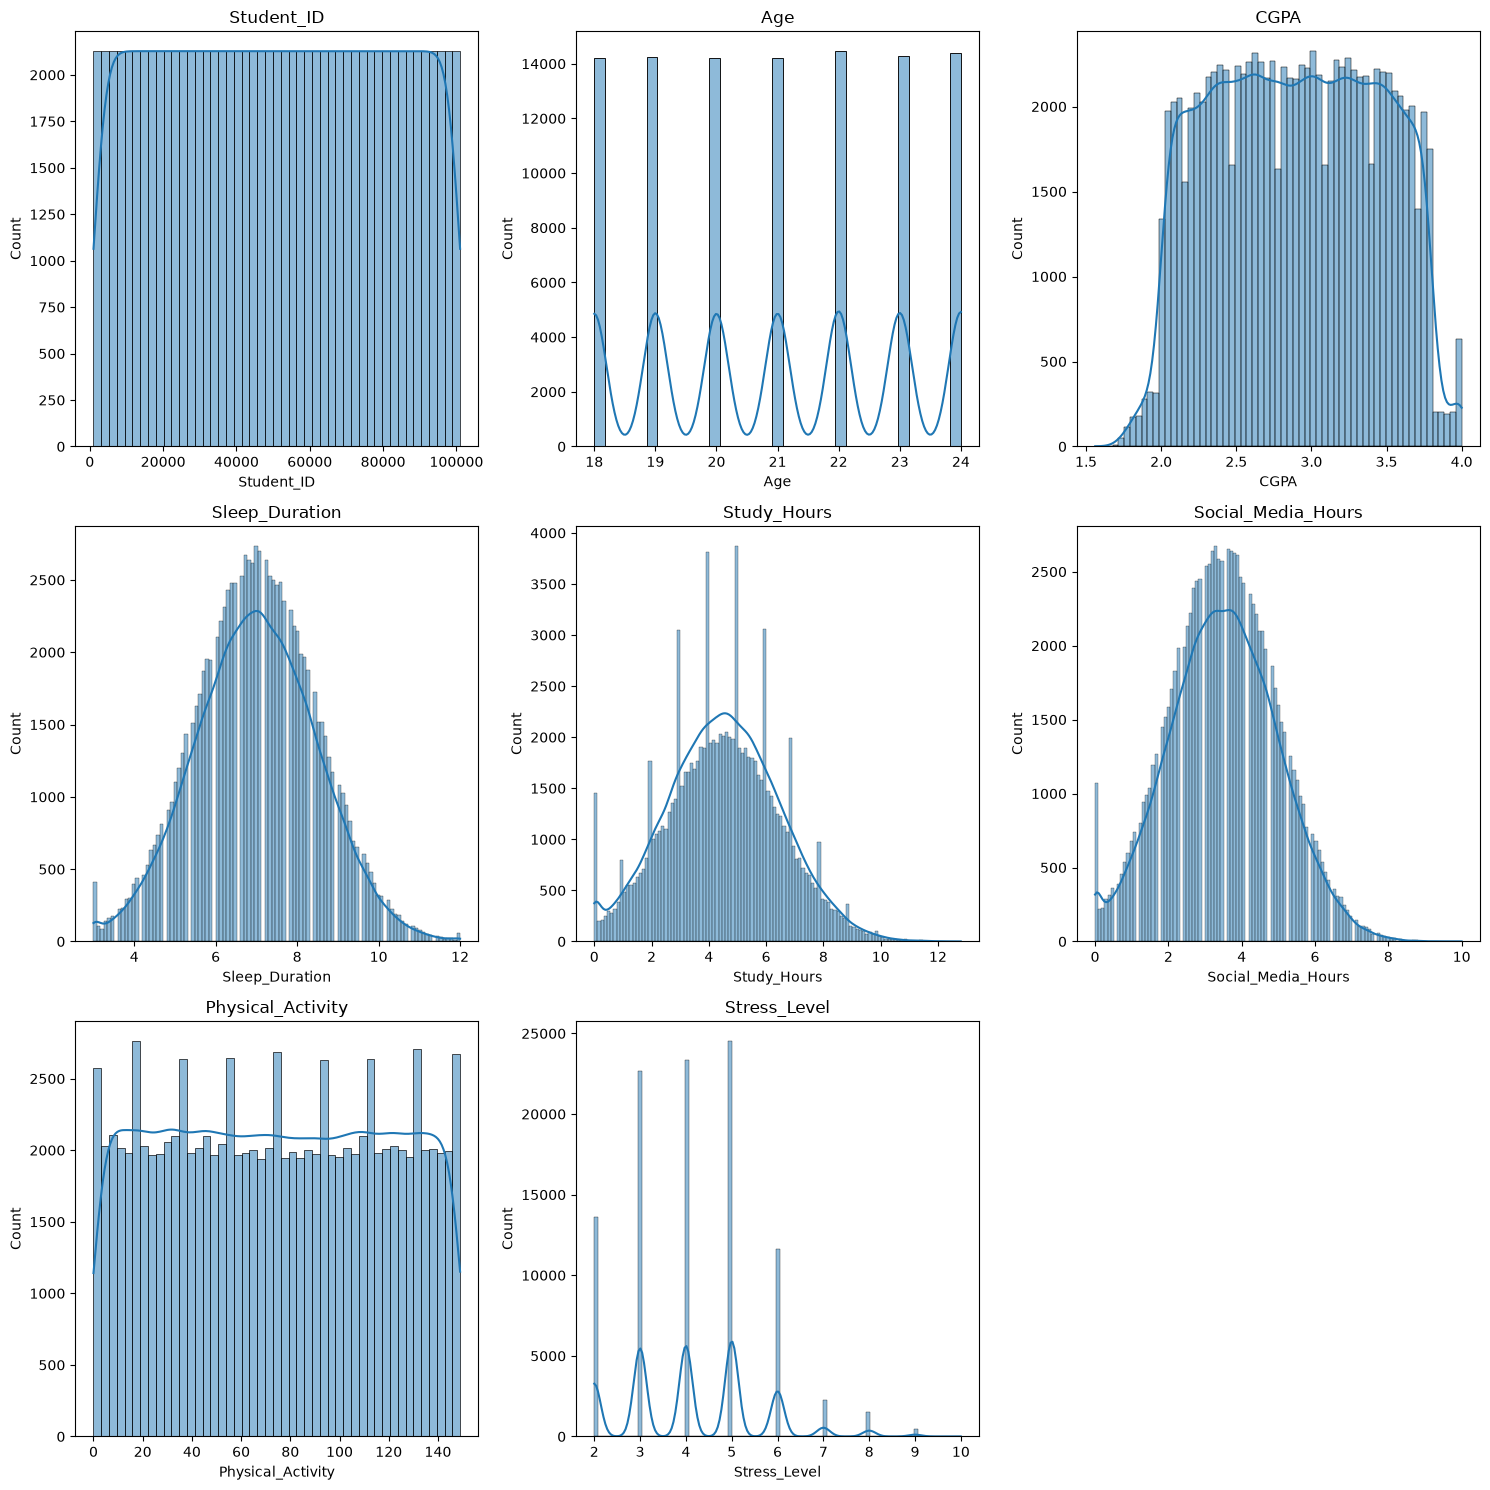

In [20]:
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15,15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(3, 3, i)
    sns.histplot(data=df[col], kde=True)
    plt.title(col)
    
plt.tight_layout()
plt.show()

## 4.0 Data Preprocessing

In [ ]:
cols = df.select_dtypes(include=['Float64', 'int64'])

Q1 = cols.quantile(0.25)
Q3 = cols.quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((cols < batas_bawah) | (cols > batas_atas)).sum()

# print('Outlier ', outlier)

hasil = pd.DataFrame({'Jumlah Outlier ': outlier})
hasil.sort_values(by='Jumlah Outlier ', ascending=False)

,Jumlah Outlier
Jumlah Outlier,NaN


In [ ]:
df['Gender'] = df['Gender'].map({'Male': 0 , 'Female': 1})
df['Depression'] = df['Depression'].map({False: 0 , True: 1})


In [23]:
df.head()

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,1001,22,1,Science,3.50,7.3,3.3,3.4,114,5,0
1,1002,20,0,Engineering,2.72,5.5,7.2,6.0,142,2,0
2,1003,20,0,Medical,3.01,5.4,2.3,1.8,137,3,0
3,1004,21,0,Engineering,3.63,8.1,2.0,4.6,130,3,0
4,1005,19,0,Arts,3.14,6.8,2.6,4.3,4,6,0


In [24]:
df_cek = df.drop(columns=['Department'])

corr_spearman = df_cek.corr(method = 'spearman')
corr_spearman

,Student_ID,Age,Gender,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
Student_ID,1.000000,0.000853,-0.002563,-0.001612,0.003649,0.002833,-0.001952,0.003301,-0.006293,-0.003663
Age,0.000853,1.000000,0.003107,0.003284,0.001617,-0.004156,-0.001175,-0.003691,0.003146,-0.007730
Gender,-0.002563,0.003107,1.000000,0.005432,-0.003187,0.000061,-0.000942,-0.004272,-0.000711,-0.004516
CGPA,-0.001612,0.003284,0.005432,1.000000,0.010703,0.082950,-0.078449,0.004595,-0.009744,-0.179578
Sleep_Duration,0.003649,0.001617,-0.003187,0.010703,1.000000,0.002590,-0.003109,0.003462,-0.201895,-0.047458
Study_Hours,0.002833,-0.004156,0.000061,0.082950,0.002590,1.000000,0.006663,-0.000929,0.005455,-0.014322
Social_Media_Hours,-0.001952,-0.001175,-0.000942,-0.078449,-0.003109,0.006663,1.000000,-0.004594,0.002174,0.017076
Physical_Activity,0.003301,-0.003691,-0.004272,0.004595,0.003462,-0.000929,-0.004594,1.000000,-0.296217,-0.013944
Stress_Level,-0.006293,0.003146,-0.000711,-0.009744,-0.201895,0.005455,0.002174,-0.296217,1.000000,0.050901
Depression,-0.003663,-0.007730,-0.004516,-0.179578,-0.047458,-0.014322,0.017076,-0.013944,0.050901,1.000000


<Axes: >

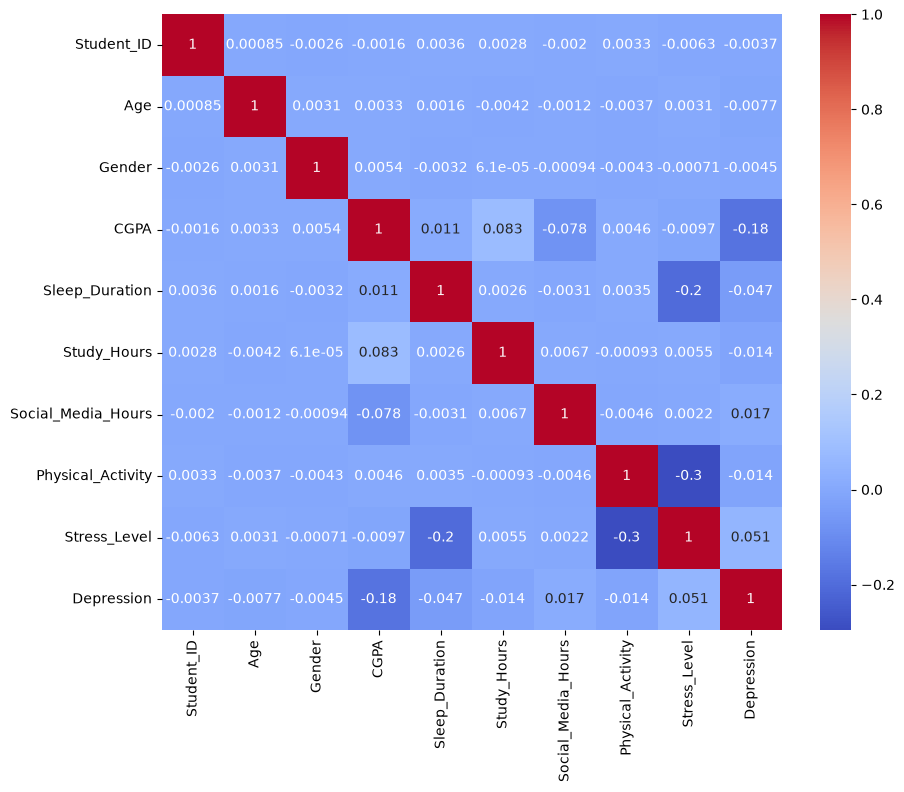

In [25]:
plt.figure(figsize=(10,8))

sns.heatmap(corr_spearman, cmap='coolwarm', fmt=".2g", annot=True)

In [26]:
X = df.drop(columns=['Department','Depression','Stress_Level','Student_ID'])
y = df['Stress_Level']

In [27]:
def split_data(X,y,train_size=0.8,random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    
    X_train, X_test = X.iloc[idx[:split_ratio]] , X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]] , y.iloc[idx[split_ratio:]]
    
    return X_train,X_test, y_train, y_test


In [28]:
X_train , X_test , y_train , y_test = split_data(X,y)


def matriks(X):
    return np.c_[np.ones(X.shape[0]), X]

def regresi(X_train,y_train,X_test):
    X_train_b = matriks(X_train)
    X_test_b = matriks(X_test)
    
    parameter_b = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train
    y_pred = X_test_b @ parameter_b
    y_pred_train = X_train_b @ parameter_b
    
    return parameter_b , y_pred, y_pred_train

parameter_b , y_pred, y_pred_train = regresi(X_train,y_train,X_test)

In [29]:
error_test = y_test - y_pred
error_test = y_train - y_pred

rss = np.sum((error_test)**2)
tss = 

SyntaxError: invalid syntax (3971730934.py, line 5)